<center> <img style="float;" src="https://oci02.img.iteso.mx/Identidades-De-Instancia/ITESO/Logos%20ITESO/Logo-ITESO-Principal.jpg" width="455" height="162.5" /> 
    
# <font color='steelblue'> Detección de fraudes en transacciones

<font color='black'>

- Ivanna herrera Ibarra
- Ana Sofía Hinojosa Bale
- Luis Fernando Márquez Bañuelos

## <font color='navy'> Librerías

In [1]:
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
from collections import Counter
import matplotlib.pyplot as plt
from collections import Counter
from IPython.display import display

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier, plot_importance
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils import validation
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.metrics import roc_auc_score, roc_curve, auc
from sklearn.metrics import precision_recall_curve, average_precision_score

warnings.filterwarnings('ignore')


## <font color='navy'> Datos

In [2]:
data_2013 = pd.read_csv('data/fraud_2013.csv')
data_2023 = pd.read_csv('data/fraud_2023.csv')

In [3]:
X_2013 = data_2013.drop(columns=['Time','Class'])
X_2023 = data_2023.drop(columns=['id','Class'])

y_2013 = data_2013['Class']
y_2023 = data_2023['Class']

## <font color='navy'> Preprocesamiento de Datos

In [4]:
# Keep only 10% of each dataset while maintaining class proportions
X_2013, _, y_2013, _ = train_test_split(
    X_2013,
    y_2013,
    train_size=0.30,
    random_state=42,
    stratify=y_2013
)

X_2023, _, y_2023, _ = train_test_split(
    X_2023,
    y_2023,
    train_size=0.30,
    random_state=42,
    stratify=y_2023
)

In [5]:
# Split the data into training and testing sets
X_train_2013, X_test_2013, y_train_2013, y_test_2013 = train_test_split(X_2013, y_2013, test_size=0.2, random_state=42, stratify=y_2013)
X_train_2023, X_test_2023, y_train_2023, y_test_2023 = train_test_split(X_2023, y_2023, test_size=0.2, random_state=42, stratify=y_2023)

In [6]:
# Standardize the "Amount" feature for both datasets
scaler_2013 = StandardScaler()
X_train_2013['Amount'] = scaler_2013.fit_transform(X_train_2013[['Amount']])
X_test_2013['Amount'] = scaler_2013.transform(X_test_2013[['Amount']])

scaler_2023 = StandardScaler()
X_train_2023['Amount'] = scaler_2023.fit_transform(X_train_2023[['Amount']])
X_test_2023['Amount'] = scaler_2023.transform(X_test_2023[['Amount']])

### <font color='skyblue'> SMOTE

In [7]:
# Create SMOTE object
smote = SMOTE(
    sampling_strategy='auto',
    k_neighbors=5,
    random_state=42
)

# Apply SMOTE to 2013 training data
X_train_2013_smote, y_train_2013_smote = smote.fit_resample(
    X_train_2013,
    y_train_2013
)

# SMOTE was previously applied to the original 2023 training data, so we can just copy the original training data for 2023
X_train_2023_smote = X_train_2023.copy()
y_train_2023_smote = y_train_2023.copy()

In [8]:
from collections import Counter

print("2013 before SMOTE:", Counter(y_train_2013))
print("2013 after SMOTE: ", Counter(y_train_2013_smote))

print("\n2023 before SMOTE:", Counter(y_train_2023))
print("2023 after SMOTE: ", Counter(y_train_2023_smote))

2013 before SMOTE: Counter({0: 68235, 1: 118})
2013 after SMOTE:  Counter({0: 68235, 1: 68235})

2023 before SMOTE: Counter({1: 68236, 0: 68235})
2023 after SMOTE:  Counter({1: 68236, 0: 68235})


## <font color='navy'> Prueba de Regresión Logística

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     17059
           1       0.94      0.57      0.71        30

    accuracy                           1.00     17089
   macro avg       0.97      0.78      0.85     17089
weighted avg       1.00      1.00      1.00     17089



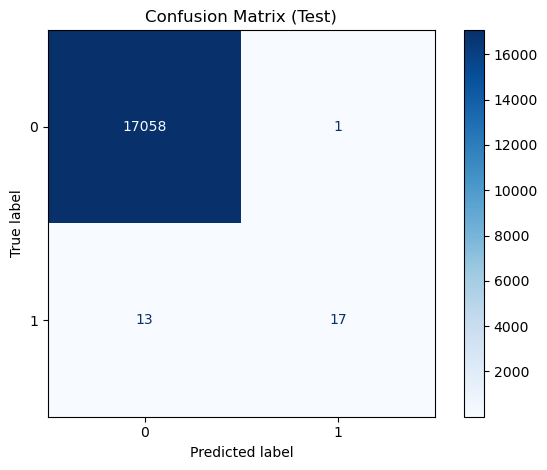

In [9]:
# Logistic Regression
model_log = LogisticRegression()
model_log.fit(X_train_2013, y_train_2013)

# Predictions
y_pred_2013 = model_log.predict(X_test_2013)

# Evaluation
print(classification_report(y_test_2013, y_pred_2013))

ConfusionMatrixDisplay.from_predictions(
    y_test_2013, y_pred_2013,
    display_labels=[0, 1],
    cmap='Blues'
)
plt.title('Confusion Matrix (Test)')

plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

           0       1.00      0.97      0.99     17059
           1       0.06      0.90      0.11        30

    accuracy                           0.97     17089
   macro avg       0.53      0.94      0.55     17089
weighted avg       1.00      0.97      0.99     17089



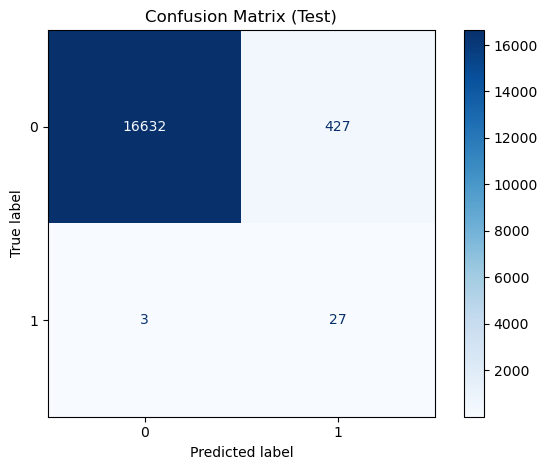

In [10]:
# Logistic Regression (SMOTE)
model_log = LogisticRegression()
model_log.fit(X_train_2013_smote, y_train_2013_smote)

# Predictions
y_pred_2013_smote = model_log.predict(X_test_2013)

# Evaluation
print(classification_report(y_test_2013, y_pred_2013_smote))

ConfusionMatrixDisplay.from_predictions(
    y_test_2013, y_pred_2013_smote,
    display_labels=[0, 1],
    cmap='Blues'
)
plt.title('Confusion Matrix (Test)')

plt.tight_layout()
plt.show()

## <font color='navy'> Modelos

### <font color='navy'> Pipeline de modelos base con SMOTE

In [11]:
log_pipeline = Pipeline([
    ('smote', SMOTE(
        sampling_strategy='auto',
        k_neighbors=5,
        random_state=42
    )),
    ('model', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])


rf_pipeline = Pipeline([
    ('smote', SMOTE(
        sampling_strategy='auto',
        k_neighbors=5,
        random_state=42
    )),
    ('model', RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

### <font color='navy'> Creación de folds y Probabilidades Out-Of-Fold 

In [12]:
# Stratafied K-Fold Cross-Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# OOF cross-validation predictions for Logistic Regression and Random Forest
log_oof = cross_val_predict(
    log_pipeline,
    X_train_2013,
    y_train_2013,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

rf_oof = cross_val_predict(
    rf_pipeline,
    X_train_2013,
    y_train_2013,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

# Create a new feature matrix for meta-model training
X_meta_train = np.column_stack([
    log_oof,
    rf_oof
])

KeyboardInterrupt: 

### <font color='navy'> XGBoost Meta-Learner

In [ ]:
meta_model = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

meta_model.fit(
    X_meta_train,
    y_train_2013
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=-1,
              num_parallel_tree=None, ...)

In [ ]:
log_pipeline.fit(
    X_train_2013,
    y_train_2013
)

rf_pipeline.fit(
    X_train_2013,
    y_train_2013
)

Pipeline(steps=[('smote', SMOTE(random_state=42)),
                ('model',
                 RandomForestClassifier(min_samples_leaf=2, n_estimators=300,
                                        n_jobs=-1, random_state=42))])

### <font color='navy'> Predicciones

In [ ]:
log_test = log_pipeline.predict_proba(
    X_test_2013
)[:, 1]

rf_test = rf_pipeline.predict_proba(
    X_test_2013
)[:, 1]

In [ ]:
X_meta_test = np.column_stack([
    log_test,
    rf_test
])

In [ ]:
y_pred_stack = meta_model.predict(X_meta_test)

y_pred_stack_prob = meta_model.predict_proba(
    X_meta_test
)[:, 1]

### <font color='navy'> Evaluación

In [ ]:
print(classification_report(
    y_test_2013,
    y_pred_stack
))

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test_2013,
        y_pred_stack_prob
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y_test_2013,
        y_pred_stack_prob
    )
)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5686
           1       0.91      1.00      0.95        10

    accuracy                           1.00      5696
   macro avg       0.95      1.00      0.98      5696
weighted avg       1.00      1.00      1.00      5696

ROC-AUC: 0.9999120647203659
PR-AUC: 0.9090909090909091


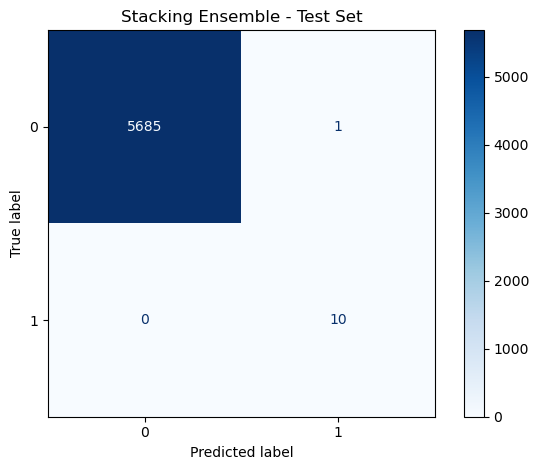

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test_2013,
    y_pred_stack,
    display_labels=[0, 1],
    cmap='Blues'
)

plt.title('Stacking Ensemble - Test Set')
plt.tight_layout()
plt.show()